In [ ]:
# Basic genetic algorithm implementation
#
# Author: Fabricio Galende Marques de Carvalho. D.Sc.
##


import numpy as np

def bin_2_int(x_bin):
    x_int = 0
    for i, bit in enumerate(x_bin):
        x_int += bit*(2**(len(x_bin)-1 - i))
    return x_int

def int_2_real(x_int, xmax, xmin, N):
    # N: Maximum natural number for this representation
    return (xmax-xmin)*x_int/N + xmin


def fitness(x,fob):
    return 1/(1+fob(x))

class Individual:
    def __init__(self, x_bin,xmax, xmin, fob, fitness):
        self._xmax = xmax
        self._xmin = xmin
        self._fob = fob
        self._fitness = fitness
        self.x_bin = x_bin
        self.x_int = bin_2_int(self.x_bin)
        self.x_r = int_2_real(self.x_int, xmax, xmin, 2**(len(self.x_bin))-1)
        self.fob = fob(self.x_r) 
        self.fitness = fitness(self.x_r, fob)

class Population:
    def __init__(self,pop_size, crom_size, xmin, xmax, fob, fitness):
        self.pop_size = pop_size
        self.individuals = []
        for _ in range(pop_size):
            x_bin = np.random.randint(0, 2, size= crom_size)
            self.individuals.append(Individual(x_bin,xmax, xmin, fob, fitness))
        

class Roulette:
    def __init__(self, population):
        self.roulette_range = []
        total_fit = 0
        for individual in population.individuals:
            total_fit += individual.fitness
        for idx, individual in enumerate(population.individuals):
            if idx == 0:
                self.roulette_range.append(individual.fitness/total_fit)
            else:
                self.roulette_range.append(self.roulette_range[idx-1] + (individual.fitness/total_fit))
        self.roulette_range[-1] = 1.0

    def spin(self):
        r = np.random.uniform(0, 1)
        for i, v in enumerate(self.roulette_range):
            if v > r:
                return i
        return len(self.roulette_range) -1
            

def mutation(individual, pm):
    x_bin_mut = []
    rng = np.random.default_rng()
    for bit in individual.x_bin:
        prob = rng.random()
        if prob > pm:
            x_bin_mut.append(bit)
        else:
            x_bin_mut.append(bit^1)
    new_individual = Individual(x_bin_mut, individual._xmax, individual._xmin, individual._fob, individual._fitness)
    return new_individual

def cross(parent_1, parent_2):
    pc = int(len(parent_1.x_bin)/2)
    child_1_bits = []
    child_2_bits = [] 
    for i in range(len(parent_1.x_bin)):
        if i < pc:
            child_1_bits.append(parent_1.x_bin[i])
            child_2_bits.append(parent_2.x_bin[i])
        else:
            child_1_bits.append(parent_2.x_bin[i])
            child_2_bits.append(parent_1.x_bin[i])

    child_1 = Individual(child_1_bits, parent_1._xmax, parent_1._xmin, parent_1._fob, parent_1._fitness)
    child_2 = Individual(child_2_bits, parent_1._xmax, parent_1._xmin, parent_1._fob, parent_1._fitness)

    return child_1, child_2
    

Best solution found:
x = 4.603659
f(x) = 0.707361


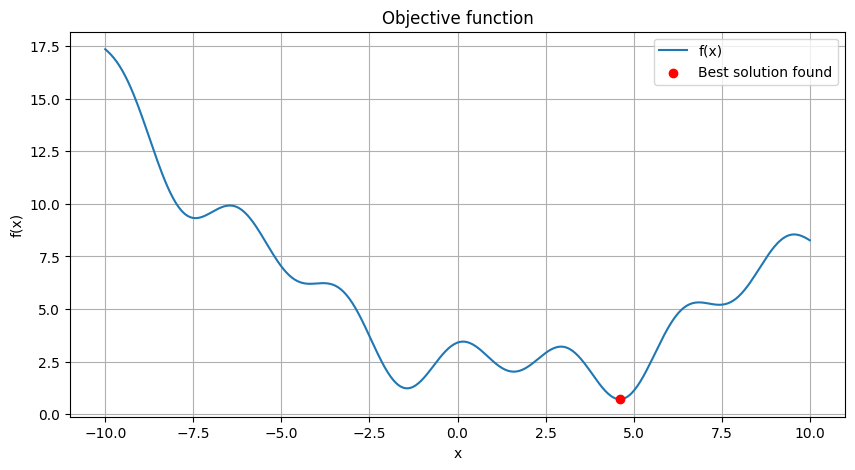

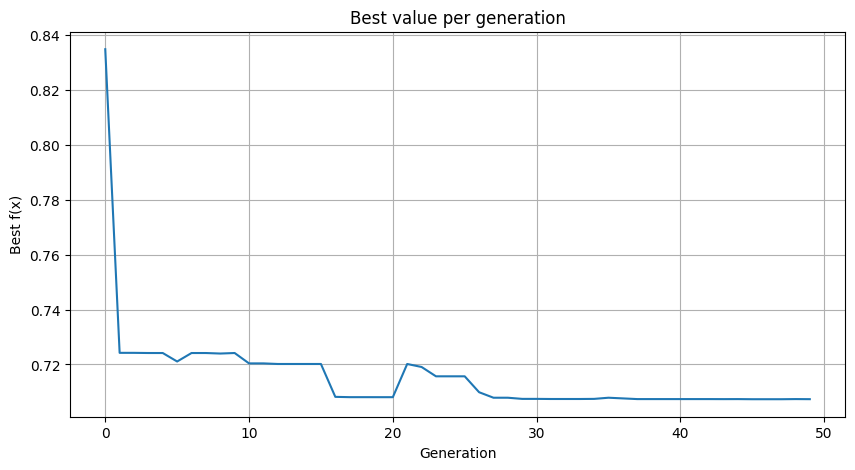

In [ ]:
# Complete Genetic Algorithm Test

from matplotlib import pyplot as plt


def fob(x):
    return 0.1*(x - 2)**2 + np.sin(x) + np.cos(2*x) + 2
    
np.random.seed(42)

xmin = -10
xmax = 10

pop_size = 100
crom_size = 50
n_generations = 50

pm = 0.01 # mutation probability 

population = Population(pop_size, crom_size,xmin, xmax, fob, fitness)

best_x_history = []
best_f_history = []

for generation in range(n_generations):

    # Best individual
    best = min(population.individuals,key=lambda ind: ind.fob)

    best_x_history.append(best.x_r)
    best_f_history.append(best.fob)

    # Selection and crossover
    roulette = Roulette(population)
    new_individuals = []

    while len(new_individuals) < pop_size:

        idx1 = roulette.spin()
        idx2 = roulette.spin()

        parent_1 = population.individuals[idx1]
        parent_2 = population.individuals[idx2]

        child_1, child_2 = cross(parent_1, parent_2)

        child_1 = mutation(child_1, pm)
        child_2 = mutation(child_2, pm)

        new_individuals.append(child_1)

        if len(new_individuals) < pop_size:
            new_individuals.append(child_2)

    # Full population replacement
    population.individuals = new_individuals

# Best final individual
best = min( population.individuals,key=lambda ind: ind.fob)

print("Best solution found:")
print(f"x = {best.x_r:.6f}")
print(f"f(x) = {best.fob:.6f}")


# Graphs

x = np.linspace(xmin, xmax, 500)
y = fob(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label="f(x)")
plt.scatter(
    [best.x_r], [best.fob],
    color="red", zorder=3,
    label="Best solution found"
)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Objective function")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(best_f_history)
plt.xlabel("Generation")
plt.ylabel("Best f(x)")
plt.title("Best value per generation")
plt.grid(True)
plt.show()
